# 03 - Geo-visualisation and recommendation

Maps and charts are produced by `src/visualize.py` from the SQL outputs. This notebook walks through them and ends with the recommendation.

In [1]:
import sys, sqlite3
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30); pd.set_option('display.float_format', '{:,.2f}'.format)
from src.config import *
from IPython.display import Image, display, HTML
show = lambda n: display(Image(filename=str(FIG_DIR / n), width=760))

## 1. Houston vs. the other big Texas metros

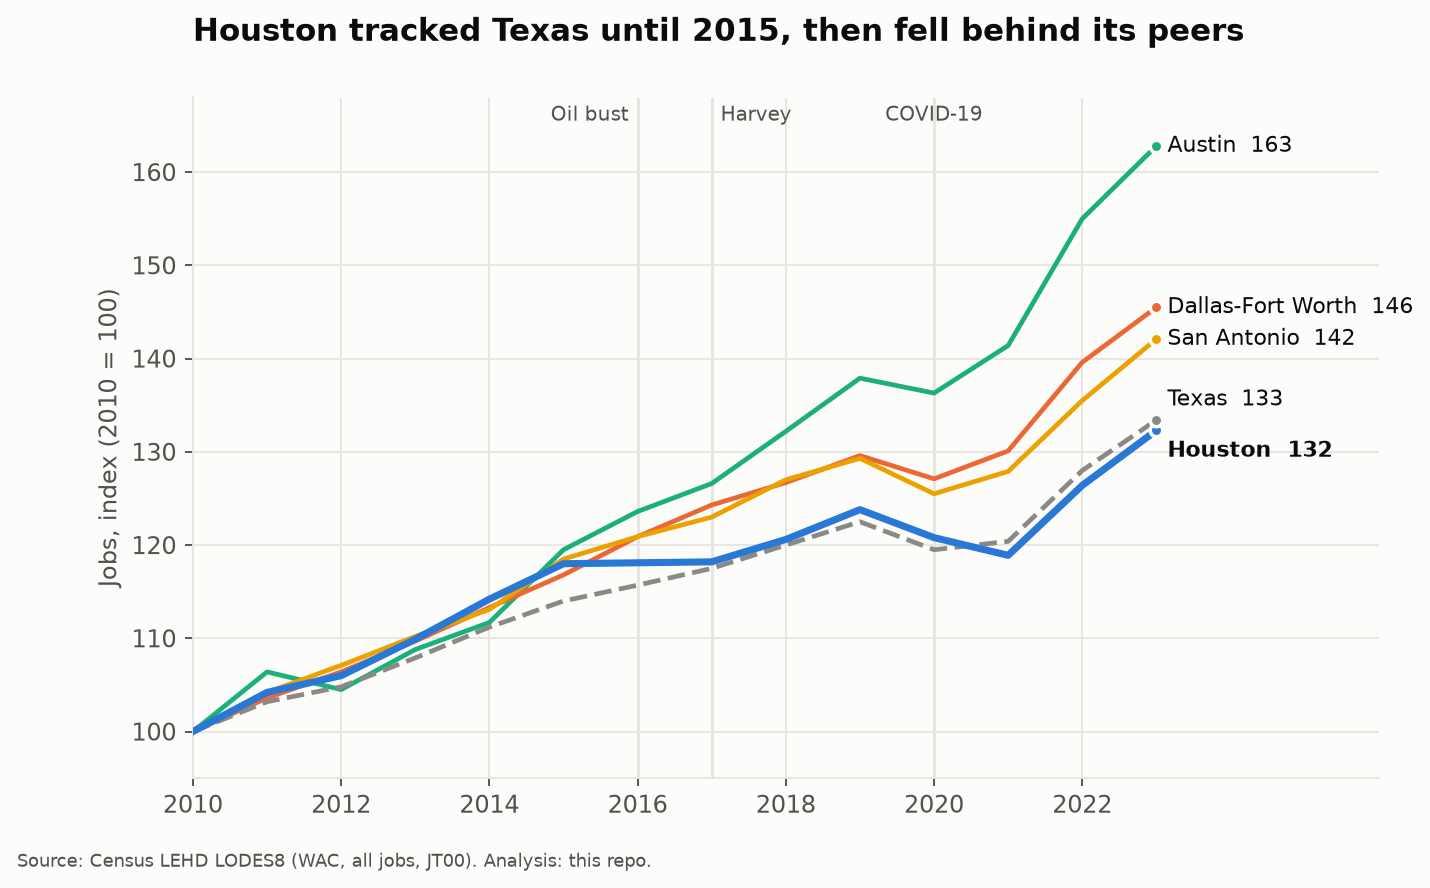

In [2]:
show('01_metro_job_growth_index.png')

Houston tracked or beat Texas through the mid-2010s, stalled with the 2015-17 oil bust and Harvey, and has grown more slowly than DFW, Austin and San Antonio since.

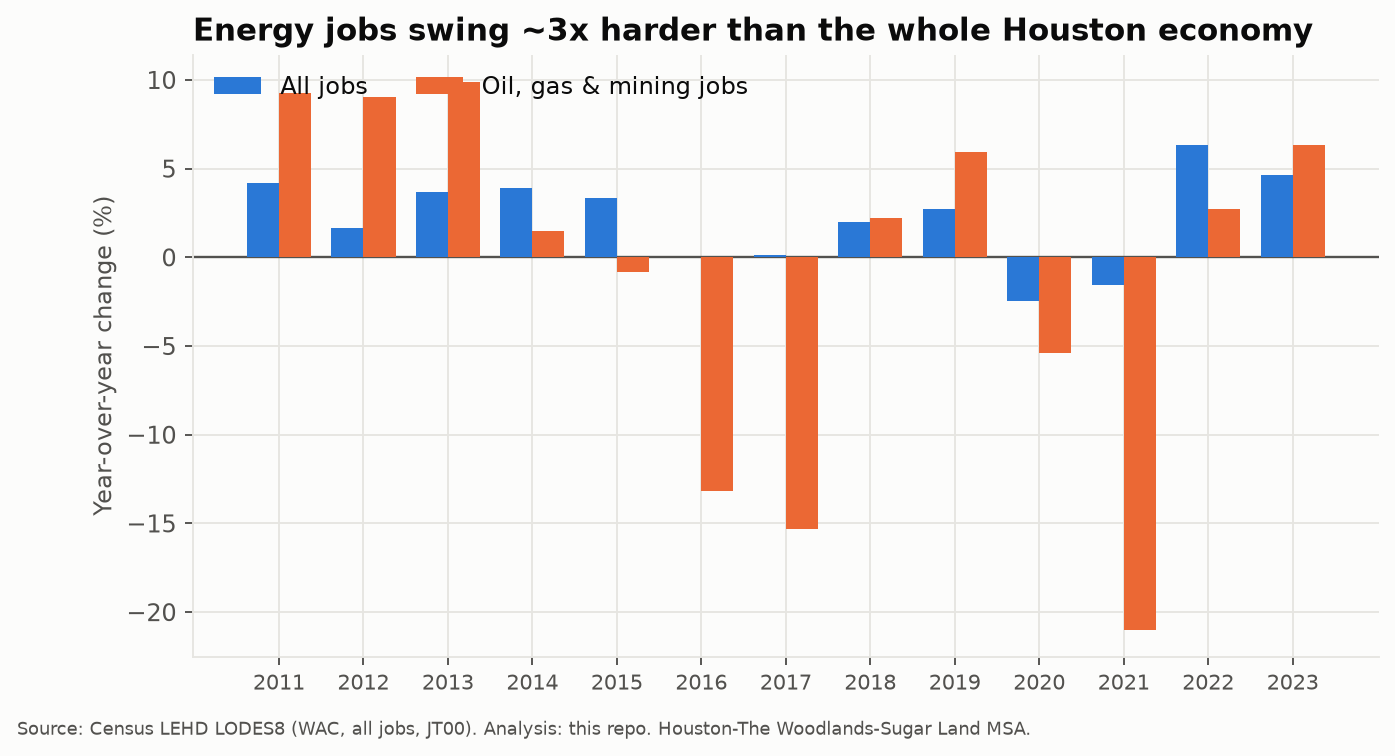

In [3]:
show('02_houston_energy_vs_total_yoy.png')

## 2. What is driving growth

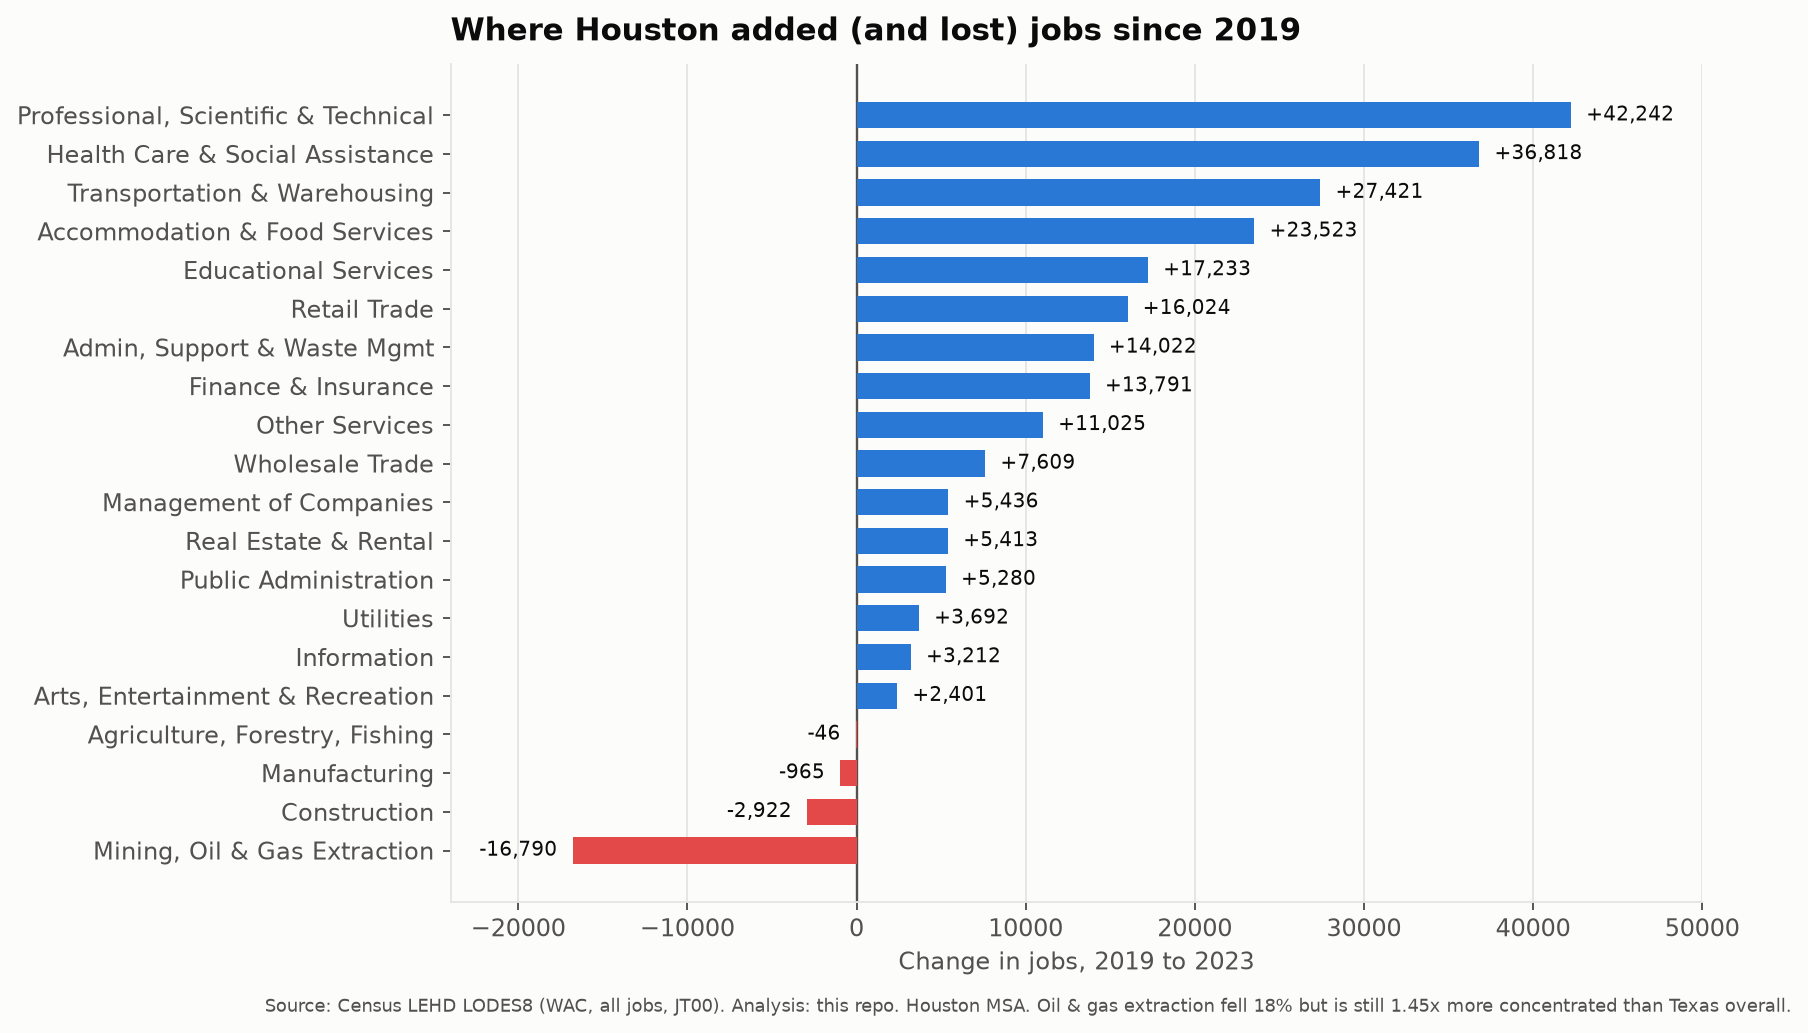

In [4]:
show('03_houston_sector_job_change.png')

## 3. Growth has moved to the suburbs

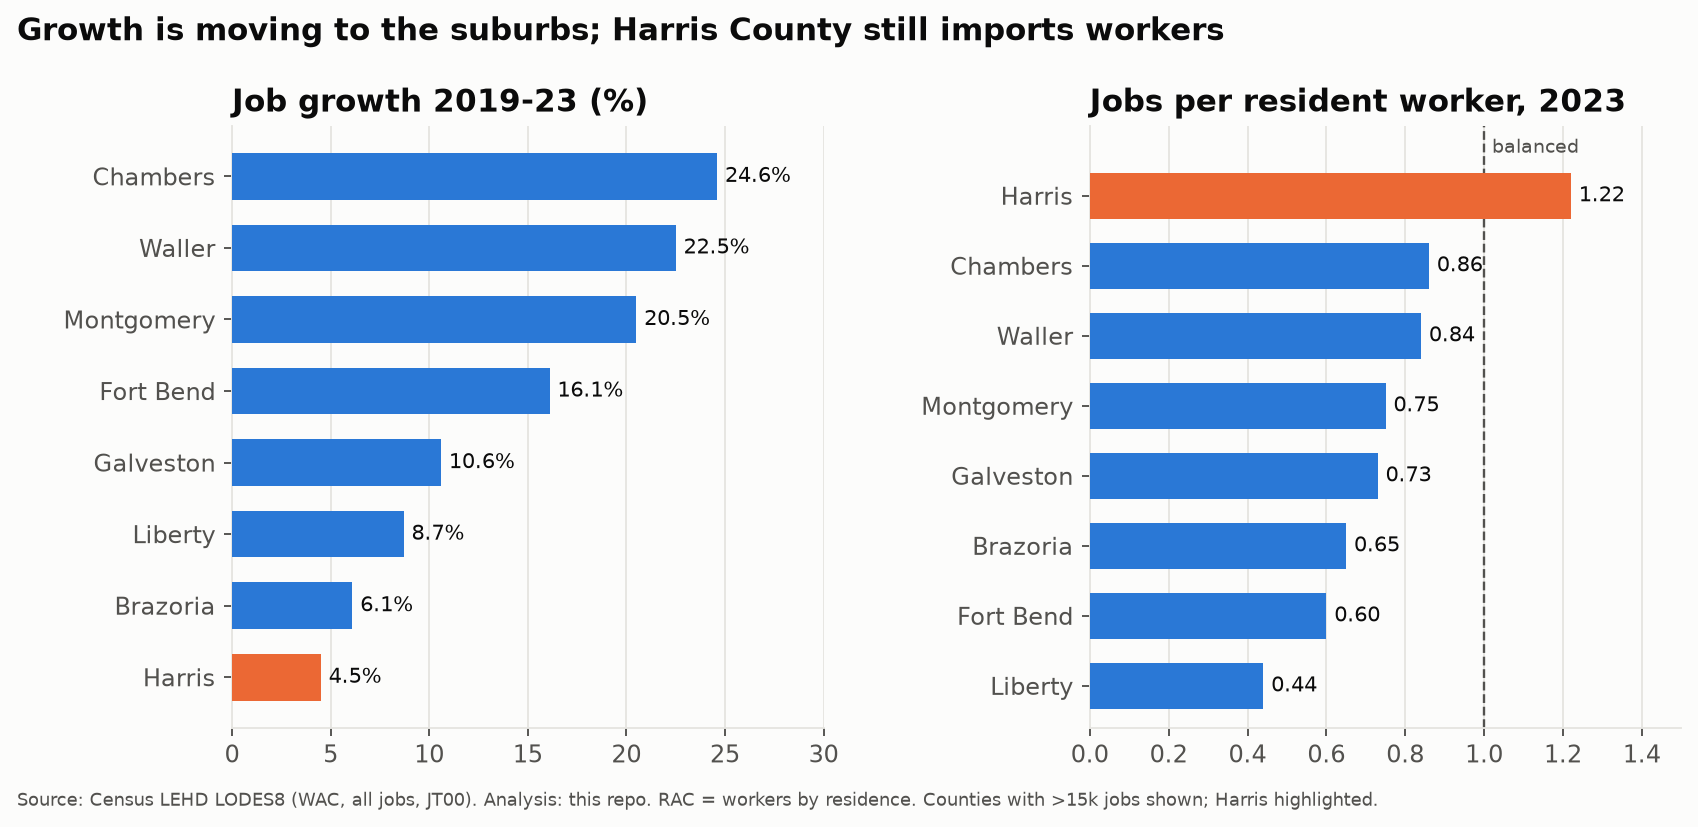

In [5]:
show('04_county_growth_and_balance.png')

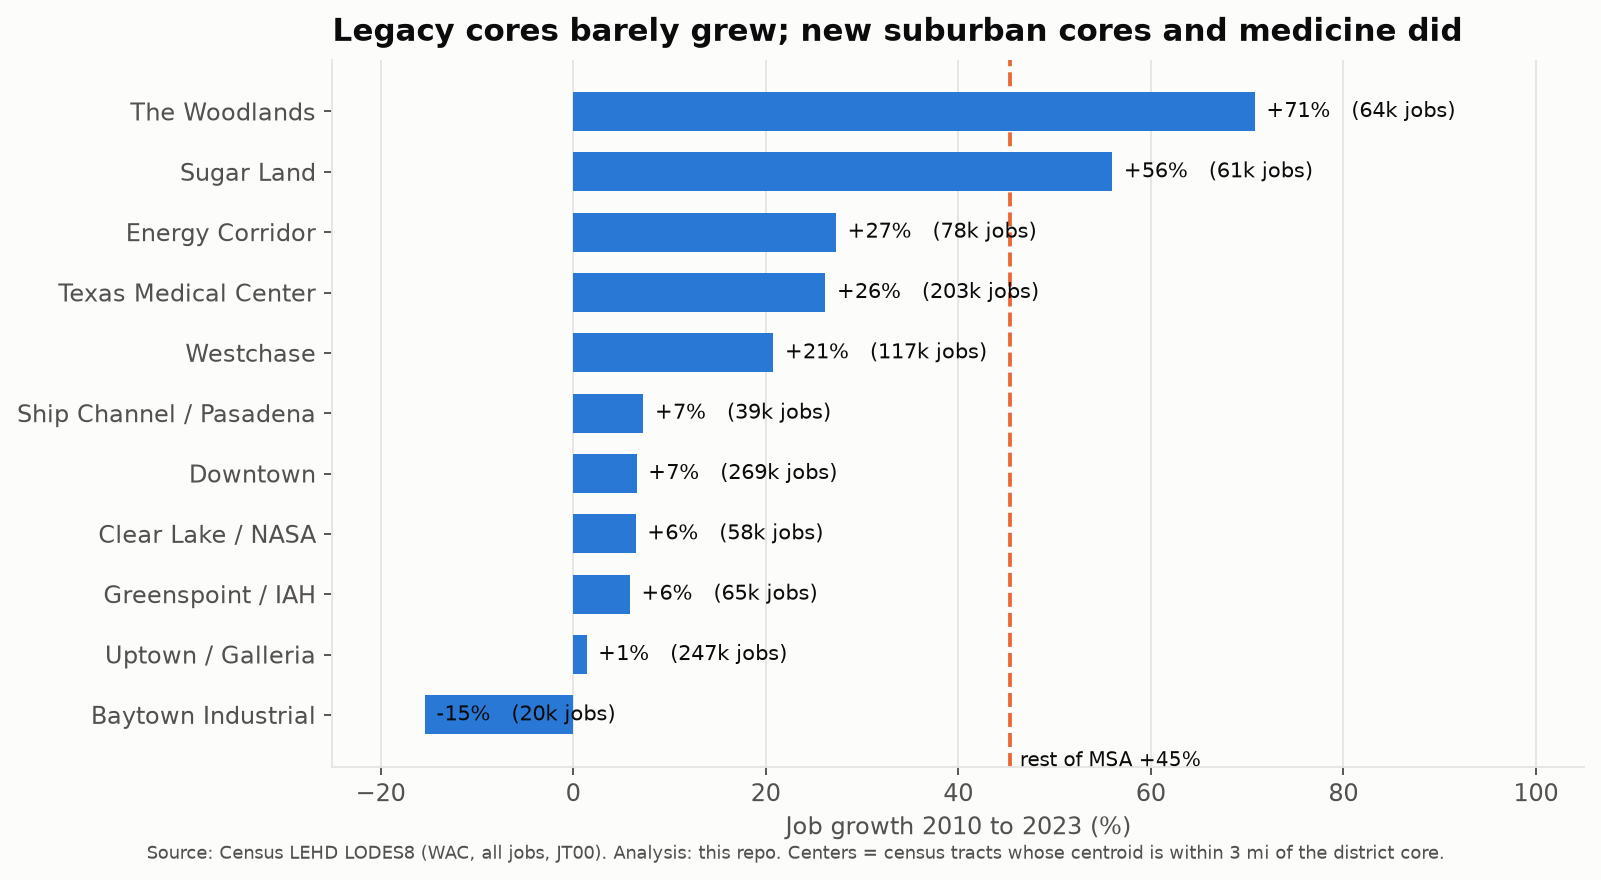

In [6]:
show('05_employment_center_growth.png')

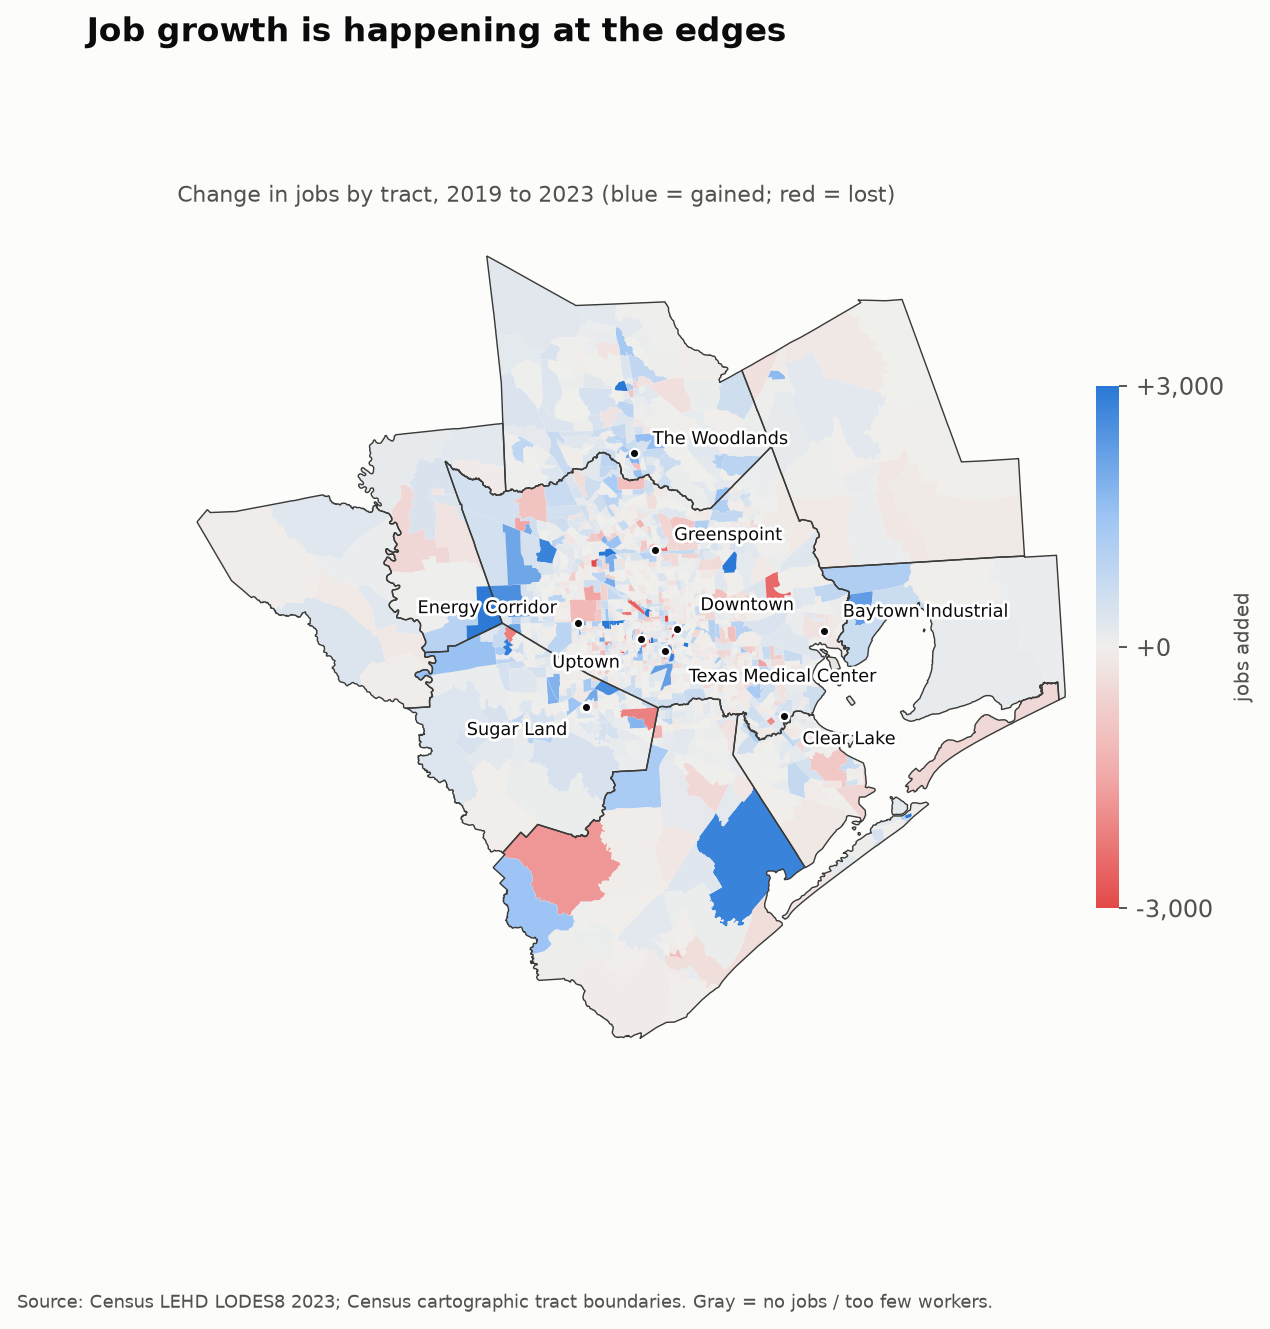

In [7]:
show('10_map_job_change_2019_23.png')

## 4. Where jobs are concentrated, and where people live relative to them

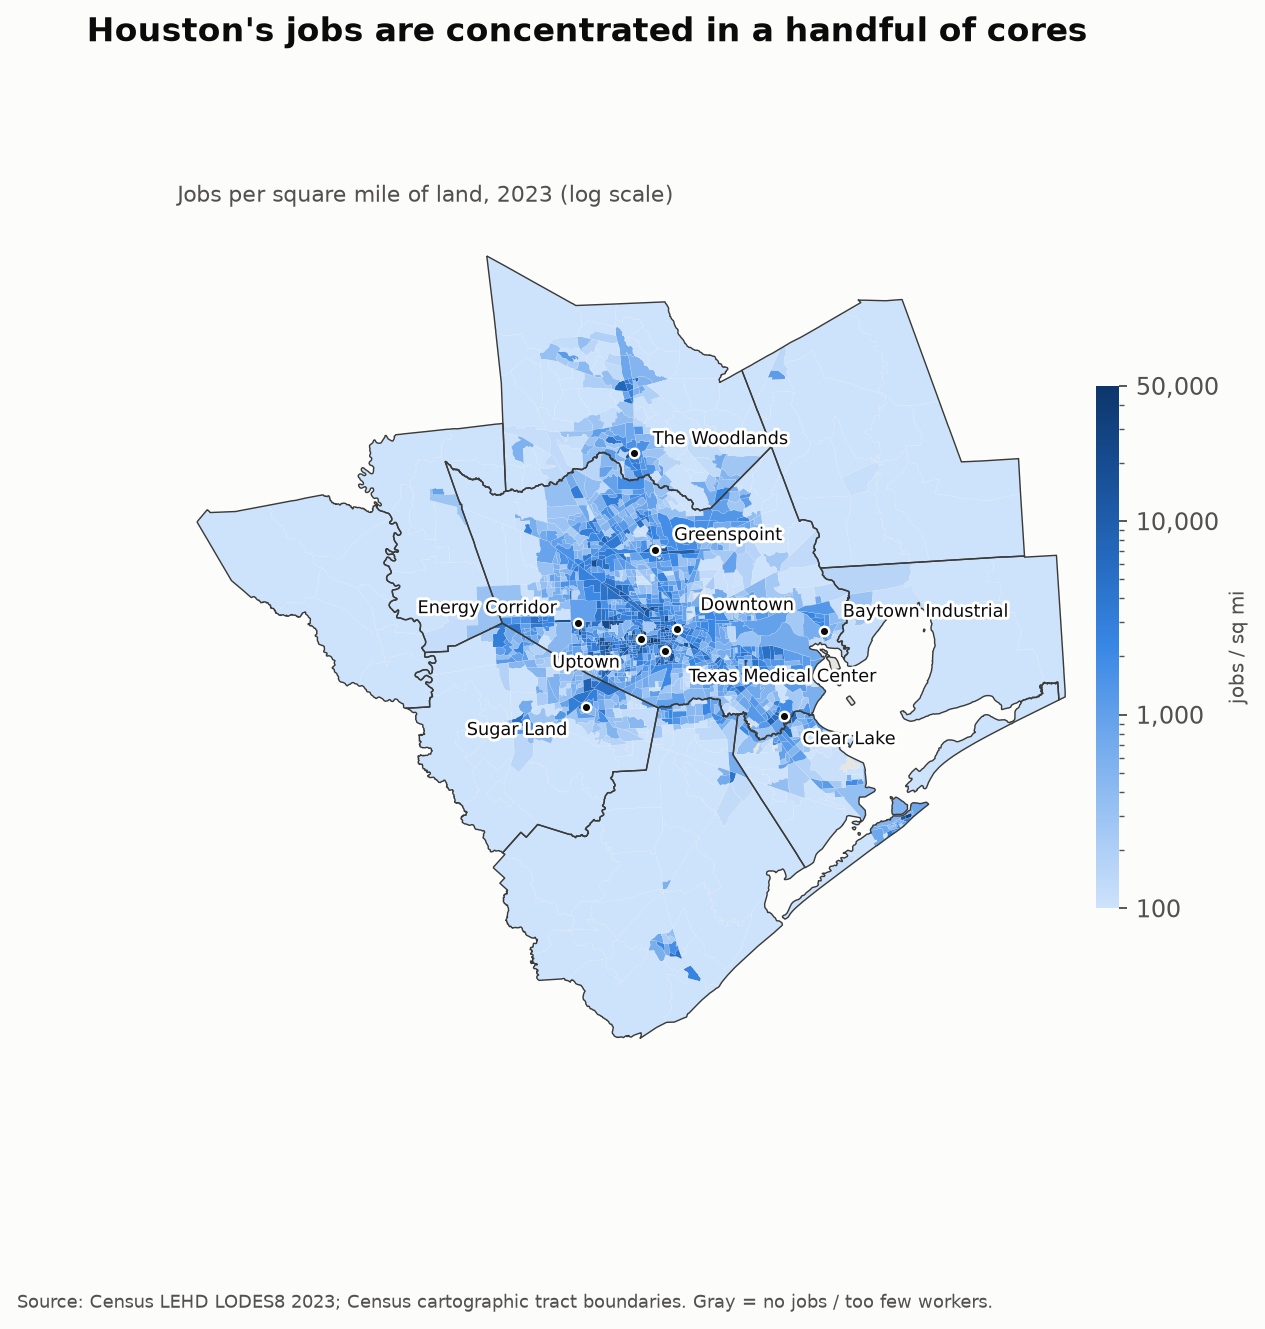

In [8]:
show('08_map_job_density.png')

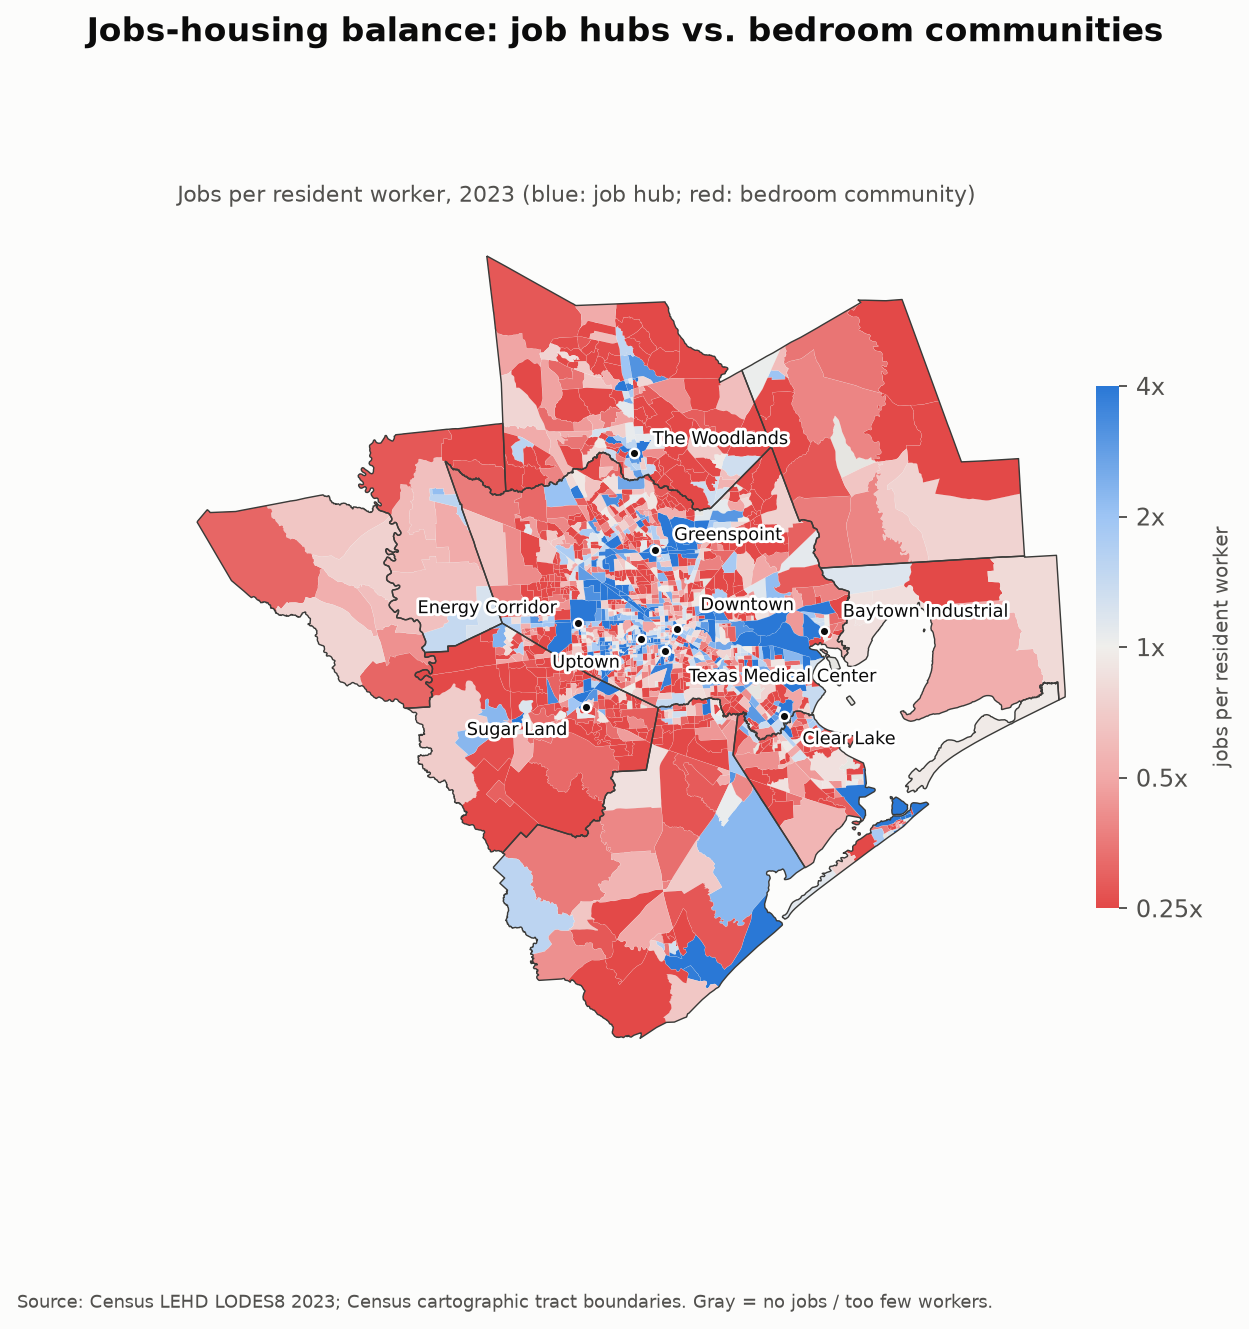

In [9]:
show('09_map_jobs_housing_balance.png')

Blue = job hubs (Downtown, Uptown/Galleria, Texas Medical Center, Westchase, Energy Corridor, Greenspoint, Ship Channel); red = bedroom tracts. The red ring around the core is where commutes start.

## 5. Commutes are becoming more regional

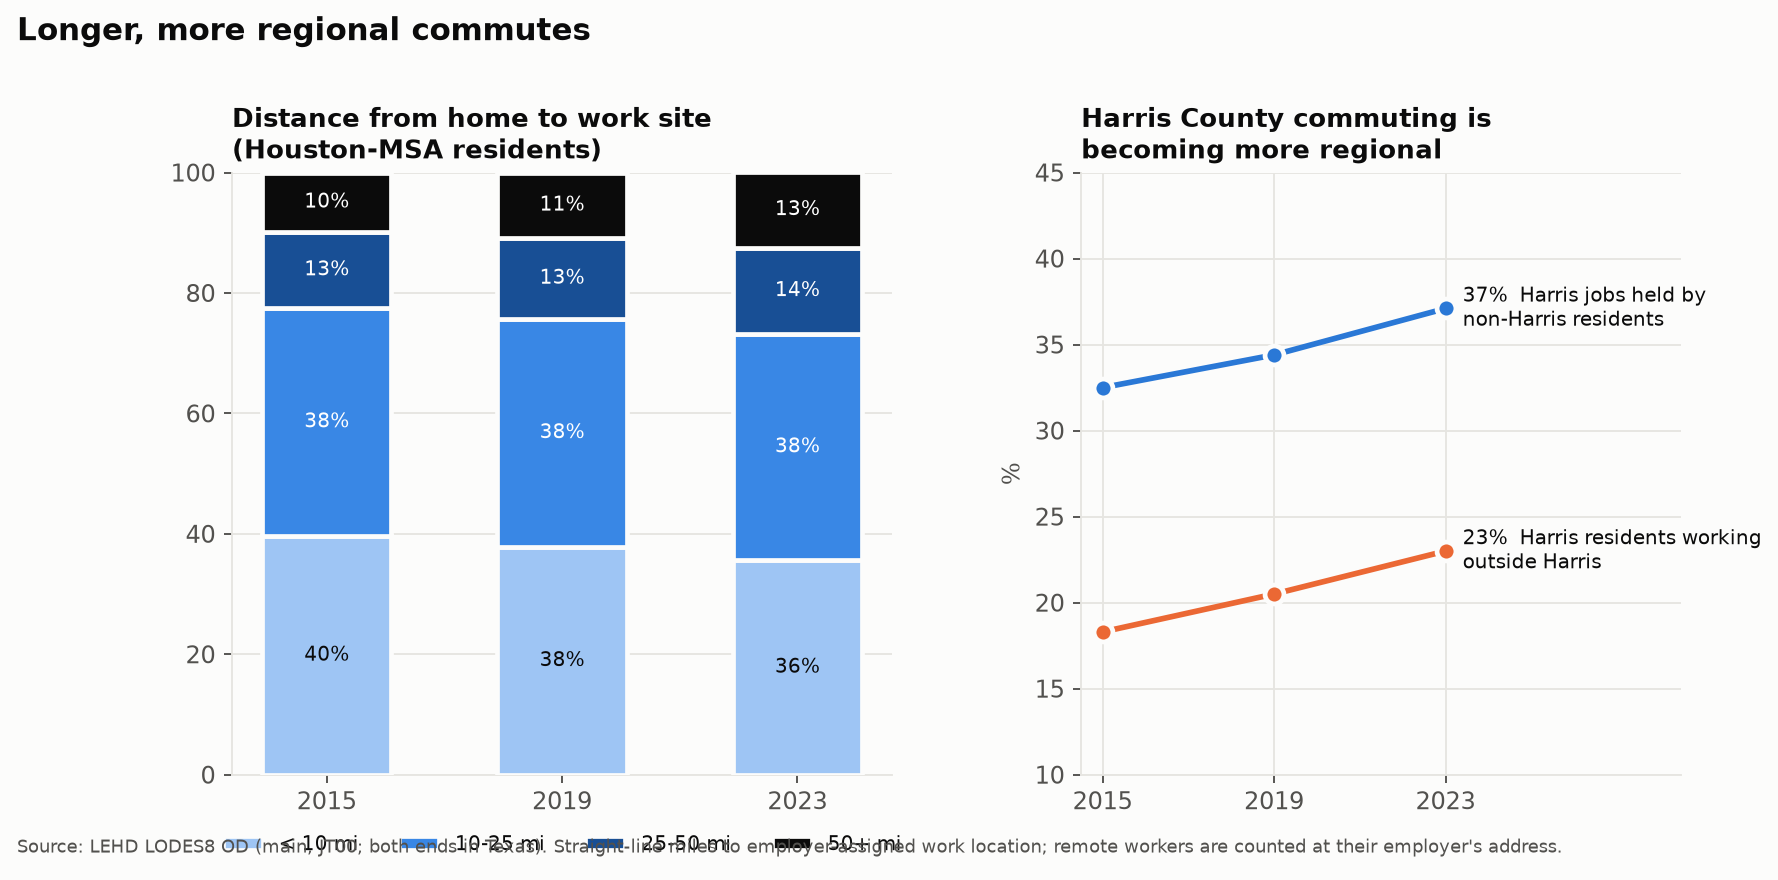

In [10]:
show('06_commute_distance_and_harris_flows.png')

## 6. Access-gap screen and recommendation

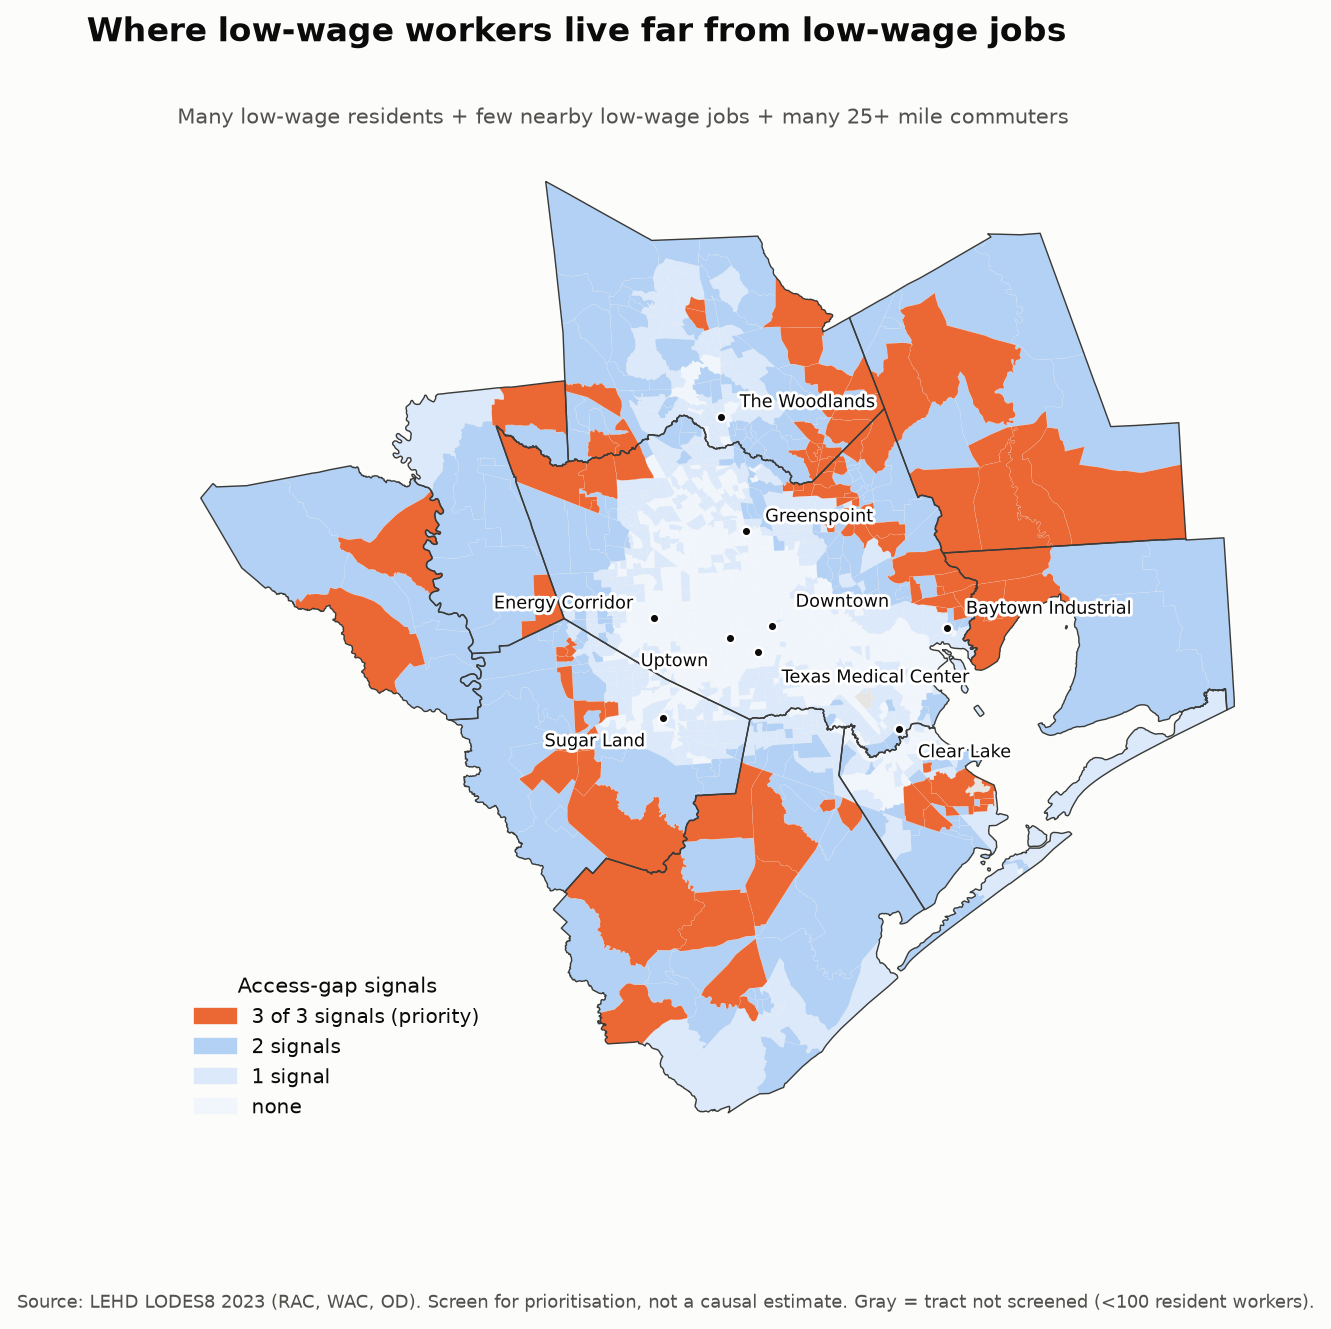

In [11]:
show('11_map_access_gap_priority_tracts.png')

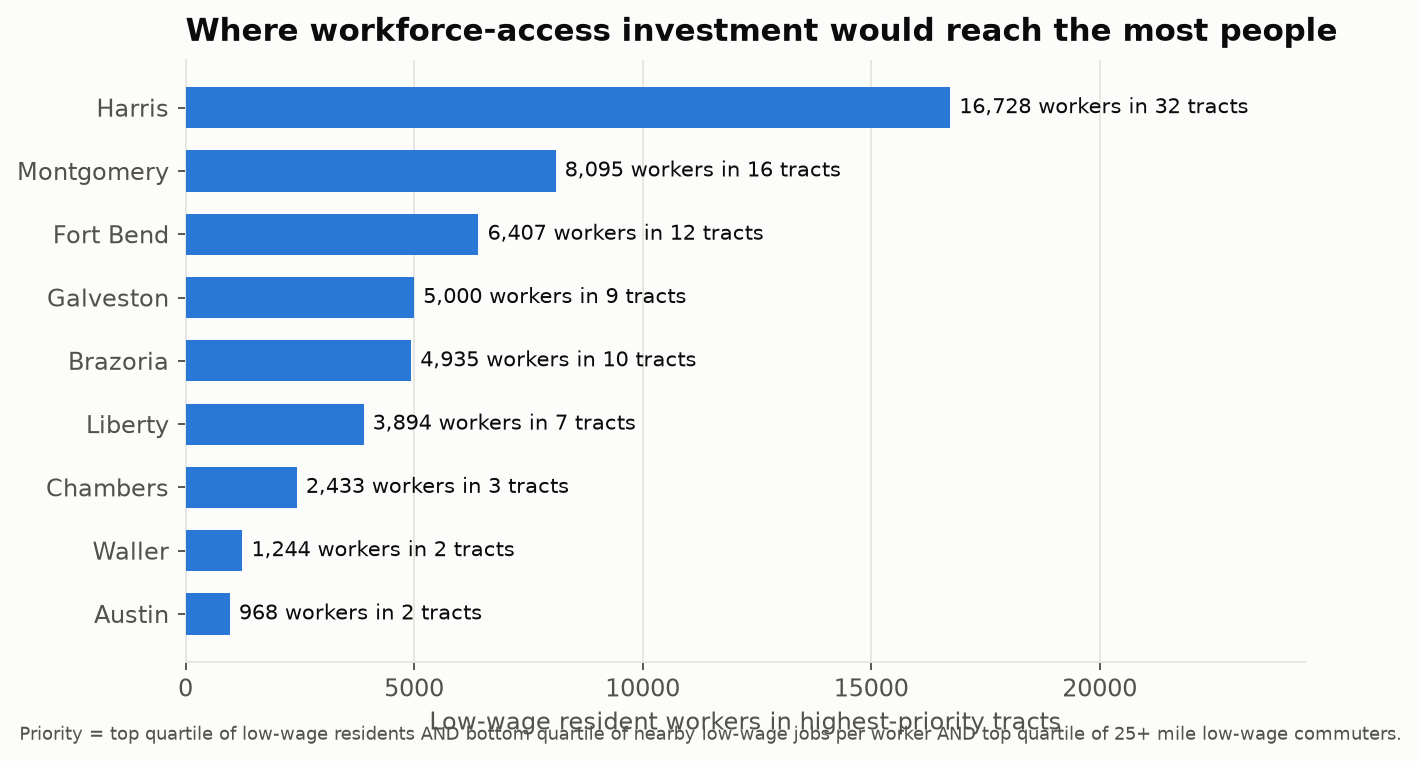

In [12]:
show('07_priority_tracts_by_county.png')

In [13]:
t = pd.read_csv(TABLE_DIR / 'tract_metrics_2023.csv', dtype={'tract': str})
p = t[t.priority_score == 3]
print(f"{len(p)} priority tracts hold {p.low_wage_residents.sum():,.0f} of {t.low_wage_residents.sum():,.0f} low-wage resident workers ({100*p.low_wage_residents.sum()/t.low_wage_residents.sum():.1f}%)")
p.groupby('county_name').agg(tracts=('tract','count'), low_wage_residents=('low_wage_residents','sum'),
    lw_jobs_per_worker_10mi=('lw_jobs_per_lw_worker_10mi','median'), pct_25plus_mi=('share_low_wage_25plus', lambda s: 100*s.median())).sort_values('low_wage_residents', ascending=False)

93 priority tracts hold 49,704 of 505,482 low-wage resident workers (9.8%)


,tracts,low_wage_residents,lw_jobs_per_worker_10mi,pct_25plus_mi
county_name,,,,
Harris,32,16728,0.78,36.52
Montgomery,16,8095,0.67,49.65
Fort Bend,12,6407,0.78,35.65
Galveston,9,5000,0.66,34.56
Brazoria,10,4935,0.54,52.30
Liberty,7,3894,0.49,67.32
Chambers,3,2433,0.82,55.29
Waller,2,1244,0.76,51.17
Austin,2,968,0.65,64.30


### Recommendation

1. **Pilot commuter access (vanpool / microtransit) on corridors linking the priority-tract clusters to their nearest job centers** - Montgomery to The Woodlands/Greenspoint, Liberty and Chambers to Baytown/Ship Channel, Brazoria to Clear Lake/Texas Medical Center, Fort Bend and NW Harris to Sugar Land/Energy Corridor.
2. **Bring jobs to workers** in Brazoria (0.70) and Liberty (0.48), where low-wage jobs per low-wage worker within 10 miles is lowest, by anchoring growth sectors (health care, logistics) there.
3. **Keep diversifying away from energy** and monitor the mining location quotient and the 20-35 mile job ring as leading indicators.
4. **Validate with vehicle-access (ACS) and transit (GTFS) data** before committing budget.

Full brief with caveats: `outputs/reports/policy_brief.md`. Interactive map: `outputs/maps/houston_jobs_interactive.html`.